In [2]:
## Important to keep in mind: 
## KNN is particularly sensitive to irrelevant variables because of the curse of dimensionality
## As a result, we must reduce the number of predictors used.
## At the start of the EDA, there are 61 columns in the data (each for one predictor)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X_train = pd.read_csv("data/processed/X_train_processed_61.csv")
y_train = pd.read_csv("data/processed/y_train.csv")

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print(X_train.head())
print(y_train.head())

print(y_train.columns)

print("\nPredictor columns:")
print(X_train.columns.tolist())

print("\nTarget columns:")
print(y_train.columns.tolist())

print("\nMissing values:")
print(X_train.isna().sum().sort_values(ascending=False))

X_train shape: (5144, 108)
y_train shape: (5144, 1)
   num__age  num__household_size  num__number_of_children  num__i2_health  \
0  0.071057            -1.107733                 0.302568       -0.150876   
1 -1.585118            -0.417212                 0.302568       -0.150876   
2  0.899145            -1.107733                -0.563548        4.490854   
3  0.126263            -0.417212                -0.563548       -0.197762   
4  0.733527            -1.107733                 0.302568       -0.150876   

   num__cantril_ladder  ord__perceived_covid_severity  \
0             0.845288                      -1.599700   
1             0.377995                      -1.599700   
2             0.845288                       0.871874   
3            -1.023884                      -0.116756   
4            -0.089298                      -1.105385   

   ord__perceived_infection_risk  ord__mask_wearing_frequency  \
0                      -1.489833                    -1.439287   
1           

In [3]:
X_train.head(10)

,num__age,num__household_size,num__number_of_children,num__i2_health,num__cantril_ladder,ord__perceived_covid_severity,ord__perceived_infection_risk,ord__mask_wearing_frequency,ord__handwashing_frequency,ord__hand_sanitizer_frequency,...,cat__d1_health_99_No,cat__d1_health_99_Yes,cat__Soc1_1_No,cat__Soc1_1_Yes,cat__Soc1_2_No,cat__Soc1_2_Yes,cat__Soc1_3_No,cat__Soc1_3_Yes,cat__had_covid_2_No,cat__had_covid_2_Yes
0,0.071057,-1.107733,0.302568,-0.150876,0.845288,-1.599700,-1.489833,-1.439287,0.476265,-2.923309,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
1,-1.585118,-0.417212,0.302568,-0.150876,0.377995,-1.599700,-0.428011,0.445803,0.476265,0.710913,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
2,0.899145,-1.107733,-0.563548,4.490854,0.845288,0.871874,0.633811,0.445803,0.476265,0.710913,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
3,0.126263,-0.417212,-0.563548,-0.197762,-1.023884,-0.116756,0.102900,0.445803,0.476265,0.710913,...,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
4,0.733527,-1.107733,0.302568,-0.150876,-0.089298,-1.105385,1.695634,0.445803,0.476265,0.710913,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
5,-0.094560,0.273309,-0.563548,-0.197762,0.377995,-0.116756,-1.489833,-0.496742,-2.333262,-1.106198,...,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
6,0.512704,0.273309,2.034799,-0.150876,0.845288,1.366188,-1.489833,0.445803,0.476265,0.710913,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
7,-1.695530,-0.417212,-0.563548,-0.088361,-0.556591,-0.116756,-0.428011,0.445803,0.476265,0.710913,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
8,0.623115,0.273309,-0.563548,-0.150876,-0.556591,-1.599700,-1.489833,-2.381831,-2.333262,-1.106198,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
9,-1.198677,-0.417212,2.034799,-0.135247,0.377995,-0.611071,-0.428011,0.445803,-2.333262,-0.197643,...,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0


In [4]:
y_train.head(5)

,low_trust
0,1
1,0
2,0
3,1
4,0


Class counts:
low_trust
0    3681
1    1463
Name: count, dtype: int64

Class percentages:
low_trust
0    71.559098
1    28.440902
Name: proportion, dtype: float64


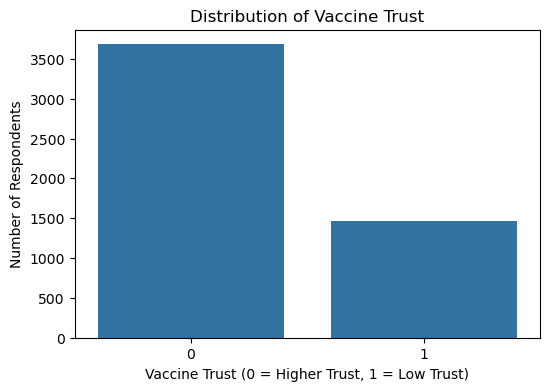

In [5]:
# Distribution of vaccine trust
y = y_train["low_trust"]

print("Class counts:")
print(y.value_counts())

print("\nClass percentages:")
print(y.value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))

sns.countplot(
    x=y,
    order=[0, 1]
)

plt.title("Distribution of Vaccine Trust")
plt.xlabel("Vaccine Trust (0 = Higher Trust, 1 = Low Trust)")
plt.ylabel("Number of Respondents")

plt.show()

In [6]:
## Since there is a class imbalance (high trust is more common), accuracy might not be the only factor we look into

In [7]:
# Distributions of numerical and ordinal predictors
num_cols = [
    col for col in X_train.columns
    if col.startswith("num__")
]

ord_cols = [
    col for col in X_train.columns
    if col.startswith("ord__")
]

cat_cols = [
    col for col in X_train.columns
    if col.startswith("cat__")
]

print("Numerical columns:", len(num_cols))
print("Ordinal columns:", len(ord_cols))
print("One-hot encoded columns:", len(cat_cols))

Numerical columns: 5
Ordinal columns: 31
One-hot encoded columns: 72


In [8]:
X_train[num_cols + ord_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
num__age,5144.0,7.286378e-17,1.000097,-1.750735,-0.867442,0.015851,0.843939,2.224085
num__household_size,5144.0,-3.038869e-17,1.000097,-1.107733,-0.417212,-0.417212,0.273309,3.725915
num__number_of_children,5144.0,4.282042e-17,1.000097,-0.563548,-0.563548,-0.563548,0.302568,3.767031
num__i2_health,5144.0,2.624477e-17,1.000097,-0.197762,-0.166505,-0.150876,-0.119619,15.430960
num__cantril_ladder,5144.0,-9.392867e-17,1.000097,-2.893055,-0.556591,0.377995,0.845288,1.779873
ord__perceived_covid_severity,5144.0,9.600062e-17,1.000097,-1.599700,-0.611071,-0.116756,0.871874,1.366188
ord__perceived_infection_risk,5144.0,-7.251846e-18,1.000097,-1.489833,-0.958922,0.102900,0.633811,1.695634
ord__mask_wearing_frequency,5144.0,8.771280e-17,1.000097,-3.324376,0.445803,0.445803,0.445803,0.445803
ord__handwashing_frequency,5144.0,-1.408930e-16,1.000097,-5.142788,0.476265,0.476265,0.476265,0.476265
ord__hand_sanitizer_frequency,5144.0,-3.556858e-16,1.000097,-2.923309,-0.197643,0.710913,0.710913,0.710913


In [9]:
# Mutual information for all columns
# Mutual information measures how much information each feature provides about the target

from sklearn.feature_selection import mutual_info_classif

y = y_train["low_trust"]

# Identify one-hot encoded columns
discrete_mask = [
    col.startswith("cat__")
    for col in X_train.columns
]

# Calculate mutual information
mi_scores = mutual_info_classif(
    X_train,
    y,
    discrete_features=discrete_mask,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": X_train.columns,
    "MI_Score": mi_scores
}).sort_values(
    "MI_Score",
    ascending=False
)

print(mi_results.head(30))

                                              Feature  MI_Score
65  cat__healthcare_system_confidence_No confidenc...  0.059120
60          cat__government_covid_response_Very badly  0.055037
33                                    ord__i11_health  0.044289
5                       ord__perceived_covid_severity  0.037179
62  cat__healthcare_system_confidence_A fair amoun...  0.031955
21                                 ord__i12_health_22  0.026318
0                                            num__age  0.026135
23                                 ord__i12_health_25  0.026069
10                      ord__avoiding_infected_people  0.025814
59       cat__government_covid_response_Somewhat well  0.025809
28                                        ord__Vent_3  0.025355
63  cat__healthcare_system_confidence_A lot of con...  0.024837
17                                 ord__i12_health_13  0.023973
25                                 ord__i12_health_27  0.023689
12                                  ord_

In [10]:
# Grouping the one-hot encoded columns back into their original variables

# Original categorical predictors
categorical_vars = [
    "gender",
    "region",
    "employment_status",
    "government_covid_response",
    "healthcare_system_confidence",
    "i9_health",
    "had_covid_2"
]

# Include the d1_health and Soc1 variables
categorical_vars += [
    f"d1_health_{i}" for i in range(1, 14)
]

categorical_vars += [
    "d1_health_98",
    "d1_health_99",
    "Soc1_1",
    "Soc1_2",
    "Soc1_3"
]

# Map encoded columns to original predictors
def get_original_feature(col):

    if col.startswith("num__"):
        return col.replace("num__", "")

    if col.startswith("ord__"):
        return col.replace("ord__", "")

    if col.startswith("cat__"):
        name = col.replace("cat__", "")

        for var in sorted(categorical_vars, key=len, reverse=True):
            if name == var or name.startswith(var + "_"):
                return var

    return col

mi_results["Original_Feature"] = (
    mi_results["Feature"].apply(get_original_feature)
)

In [11]:
mi_grouped = (
    mi_results
    .groupby("Original_Feature")["MI_Score"]
    .max()
    .sort_values(ascending=False)
)

print(mi_grouped.head(25))

Original_Feature
healthcare_system_confidence    0.059120
government_covid_response       0.055037
i11_health                      0.044289
perceived_covid_severity        0.037179
i12_health_22                   0.026318
age                             0.026135
i12_health_25                   0.026069
avoiding_infected_people        0.025814
Vent_3                          0.025355
i12_health_13                   0.023973
i12_health_27                   0.023689
i12_health_6                    0.023345
perceived_infection_risk        0.022347
i12_health_26                   0.021791
i12_health_15                   0.021670
i12_health_11                   0.019083
i12_health_14                   0.018981
employment_status               0.018829
hand_sanitizer_frequency        0.018127
i12_health_23                   0.016241
i12_health_28                   0.014068
number_of_children              0.012573
PHQ4_4                          0.011917
i9_health                       0.011287

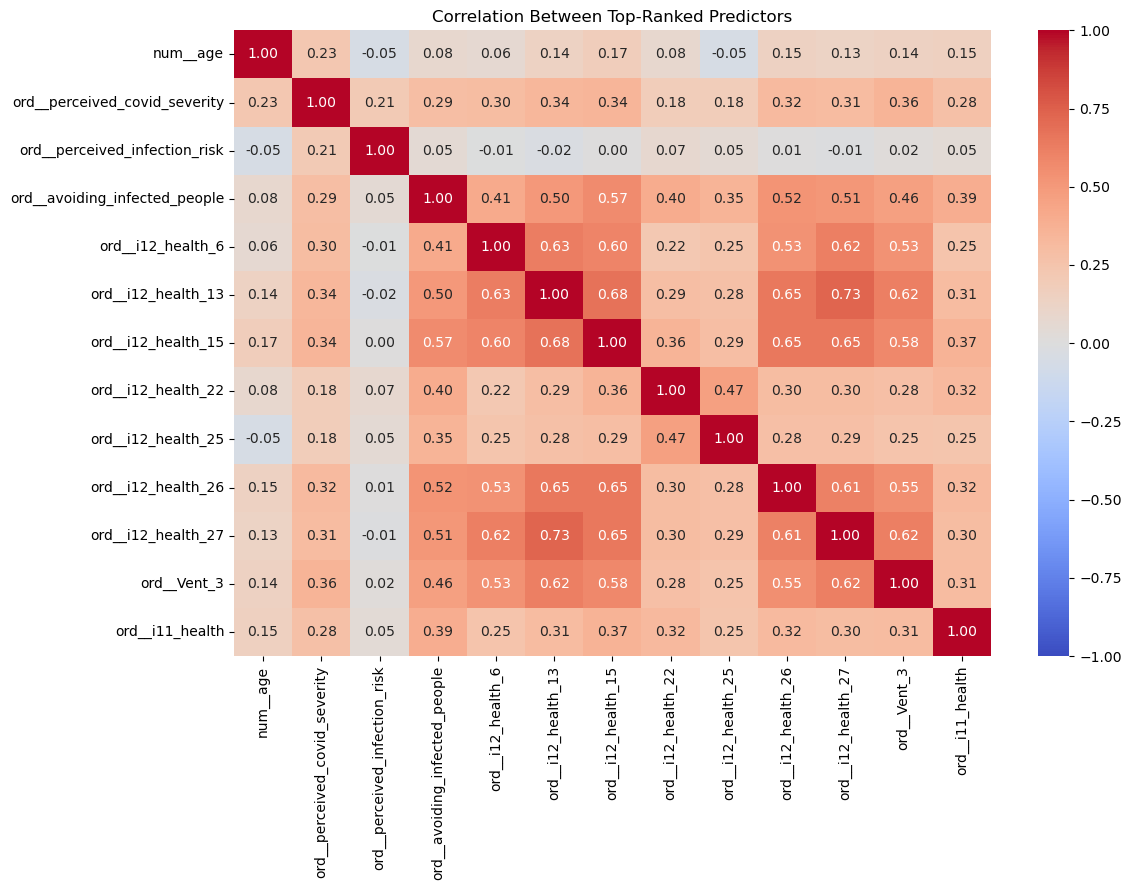

In [12]:
# top 15 features (all features with > 0.02 MI)
top_features = mi_grouped.head(15).index.tolist()

selected_cols = [
    col for col in X_train.columns
    if col.startswith(("num__", "ord__"))
    and col.split("__", 1)[1] in top_features
]

corr_matrix = X_train[selected_cols].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Top-Ranked Predictors")
plt.tight_layout()
plt.show()

In [13]:
print(corr_matrix)

                               num__age  ord__perceived_covid_severity  \
num__age                       1.000000                       0.232349   
ord__perceived_covid_severity  0.232349                       1.000000   
ord__perceived_infection_risk -0.051635                       0.205475   
ord__avoiding_infected_people  0.084735                       0.291633   
ord__i12_health_6              0.063181                       0.297225   
ord__i12_health_13             0.136621                       0.336457   
ord__i12_health_15             0.173236                       0.344529   
ord__i12_health_22             0.083643                       0.181794   
ord__i12_health_25            -0.054068                       0.180527   
ord__i12_health_26             0.147612                       0.315159   
ord__i12_health_27             0.129922                       0.310752   
ord__Vent_3                    0.143557                       0.358779   
ord__i11_health                0.15241

In [14]:
# IMPORTANT: The correlation matrix does not include the two categorical variables.
# Their redundancy has not been assessed yet.

In [15]:
# Usually, we would keep all values if their correlations do not exceed 0.8
# In this case, none of them do, however, there are many correlations between 0.6 and 0.75
# These values are big enough to look into further.
# Particularly, the i12_health variables are moderately-to-strongly correlated with each other.

In [16]:
# We divide the variables into groups:
# Group 1 - Strong candidates: Relatively high MI and not obviously redundant with each other.
# Group 2 - Potentially overlapping: Worth investigating, but probalby will not need all
# Group 3 - Lower priority: Variables outside the top 15 MI. Will wait.

                               num__age  num__household_size  \
num__age                       1.000000            -0.377952   
num__household_size           -0.377952             1.000000   
num__number_of_children       -0.267972             0.534793   
num__i2_health                -0.025966             0.018981   
num__cantril_ladder            0.188752            -0.028537   
ord__perceived_covid_severity  0.232349            -0.057272   
ord__perceived_infection_risk -0.051635             0.047350   
ord__mask_wearing_frequency    0.056873            -0.026821   
ord__handwashing_frequency     0.050735            -0.033995   
ord__hand_sanitizer_frequency  0.077326            -0.024039   
ord__avoiding_infected_people  0.084735            -0.062523   
ord__i12_health_4              0.124969            -0.086384   
ord__i12_health_6              0.063181            -0.021366   
ord__i12_health_7              0.037299            -0.030123   
ord__i12_health_8              0.178995 

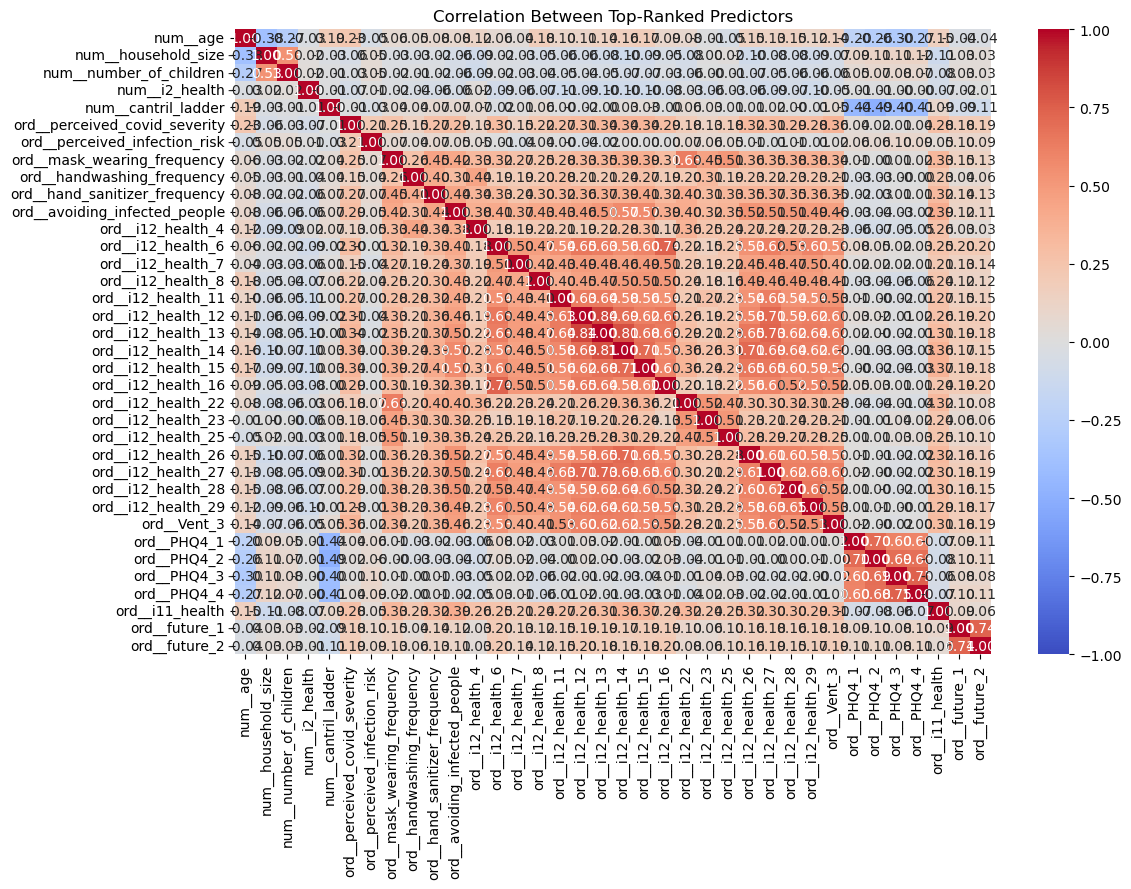

In [17]:
cols = [
    col for col in X_train.columns
    if col.startswith(("num__", "ord__"))
]

corr_matrix_full = X_train[cols].corr()

print(corr_matrix_full)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix_full,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Top-Ranked Predictors")
plt.tight_layout()
plt.show()

In [18]:
# Assessing categorical variable correlation

# Identify the one-hot columns
health_cols = [
    col for col in X_train.columns
    if col.startswith("cat__healthcare_system_confidence_")
]

gov_cols = [
    col for col in X_train.columns
    if col.startswith("cat__government_covid_response_")
]

# Reconstruct categorical variables
health_confidence = (
    X_train[health_cols]
    .idxmax(axis=1)
    .str.replace(
        "cat__healthcare_system_confidence_",
        "",
        regex=False
    )
)

gov_response = (
    X_train[gov_cols]
    .idxmax(axis=1)
    .str.replace(
        "cat__government_covid_response_",
        "",
        regex=False
    )
)

In [19]:
from scipy.stats import chi2_contingency

# Contingency table
contingency_table = pd.crosstab(
    health_confidence,
    gov_response
)

# Chi-square test
chi2, p, dof, expected = chi2_contingency(
    contingency_table
)

# Cramér's V
n = contingency_table.to_numpy().sum()

r, k = contingency_table.shape

cramers_v = np.sqrt(
    (chi2 / n) / min(r - 1, k - 1)
)

print("Cramér's V:", round(cramers_v, 4))
print("P-value:", p)

Cramér's V: 0.5947
P-value: 0.0


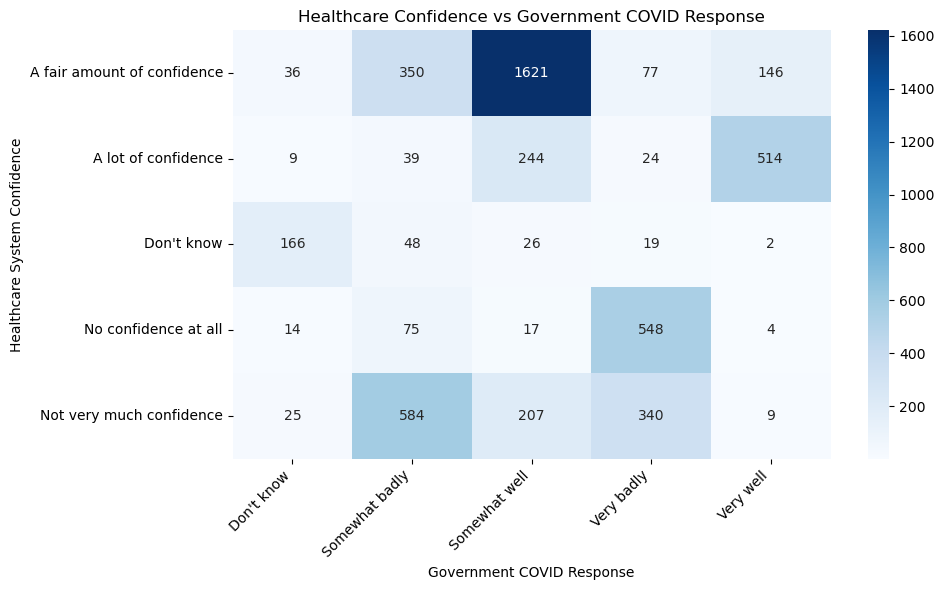

In [20]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    contingency_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Healthcare Confidence vs Government COVID Response"
)

plt.xlabel("Government COVID Response")
plt.ylabel("Healthcare System Confidence")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [21]:
# Even if these two categorical variables seem to be correlated, they are both the ones that show the highest MI value.
# Therefore, we decide to keep them in the analysis.
# One of them might be swapped out in the future.

In [22]:
# Predictors selected (at leat preliminary):
# healthcare system confidence, government covid response, i11 health, perceived covid severity
# i12 health 22, age, i12 health 25, avoiding infected people, i12 health 13, perceived infection risk, employment status, hand sanitizer frequency
# Reason for this selection: High or relatively high MI, trying to keep correlations out

In [23]:
selected_features = [
    "healthcare_system_confidence",
    "government_covid_response",
    "i11_health",
    "perceived_covid_severity",
    "i12_health_22",
    "age",
    "i12_health_25",
    "avoiding_infected_people",
    "i12_health_13",
    "perceived_infection_risk",
    "employment_status",
    "hand_sanitizer_frequency"
]

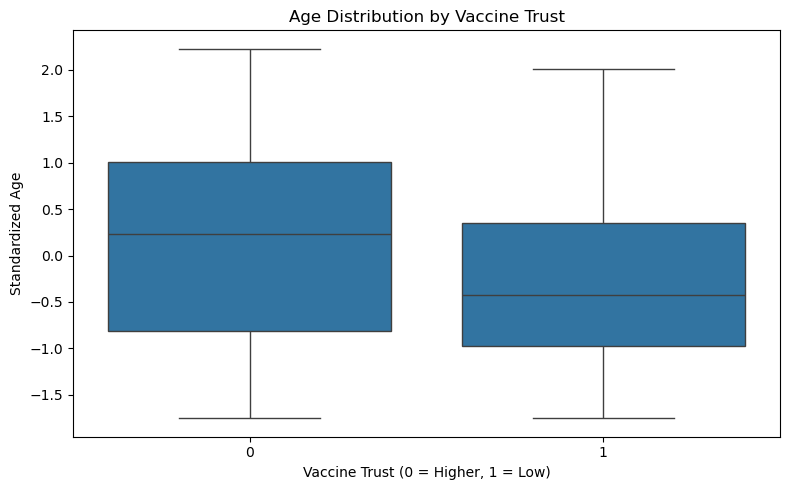

In [24]:
eda_data = X_train.copy()
eda_data["low_trust"] = y_train["low_trust"].to_numpy()

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_data,
    x="low_trust",
    y="num__age"
)

plt.title("Age Distribution by Vaccine Trust")
plt.xlabel("Vaccine Trust (0 = Higher, 1 = Low)")
plt.ylabel("Standardized Age")

plt.tight_layout()
plt.show()

In [25]:
ordinal_features = [
    "i11_health",
    "perceived_covid_severity",
    "i12_health_22",
    "i12_health_25",
    "avoiding_infected_people",
    "i12_health_13",
    "perceived_infection_risk",
    "hand_sanitizer_frequency"
]

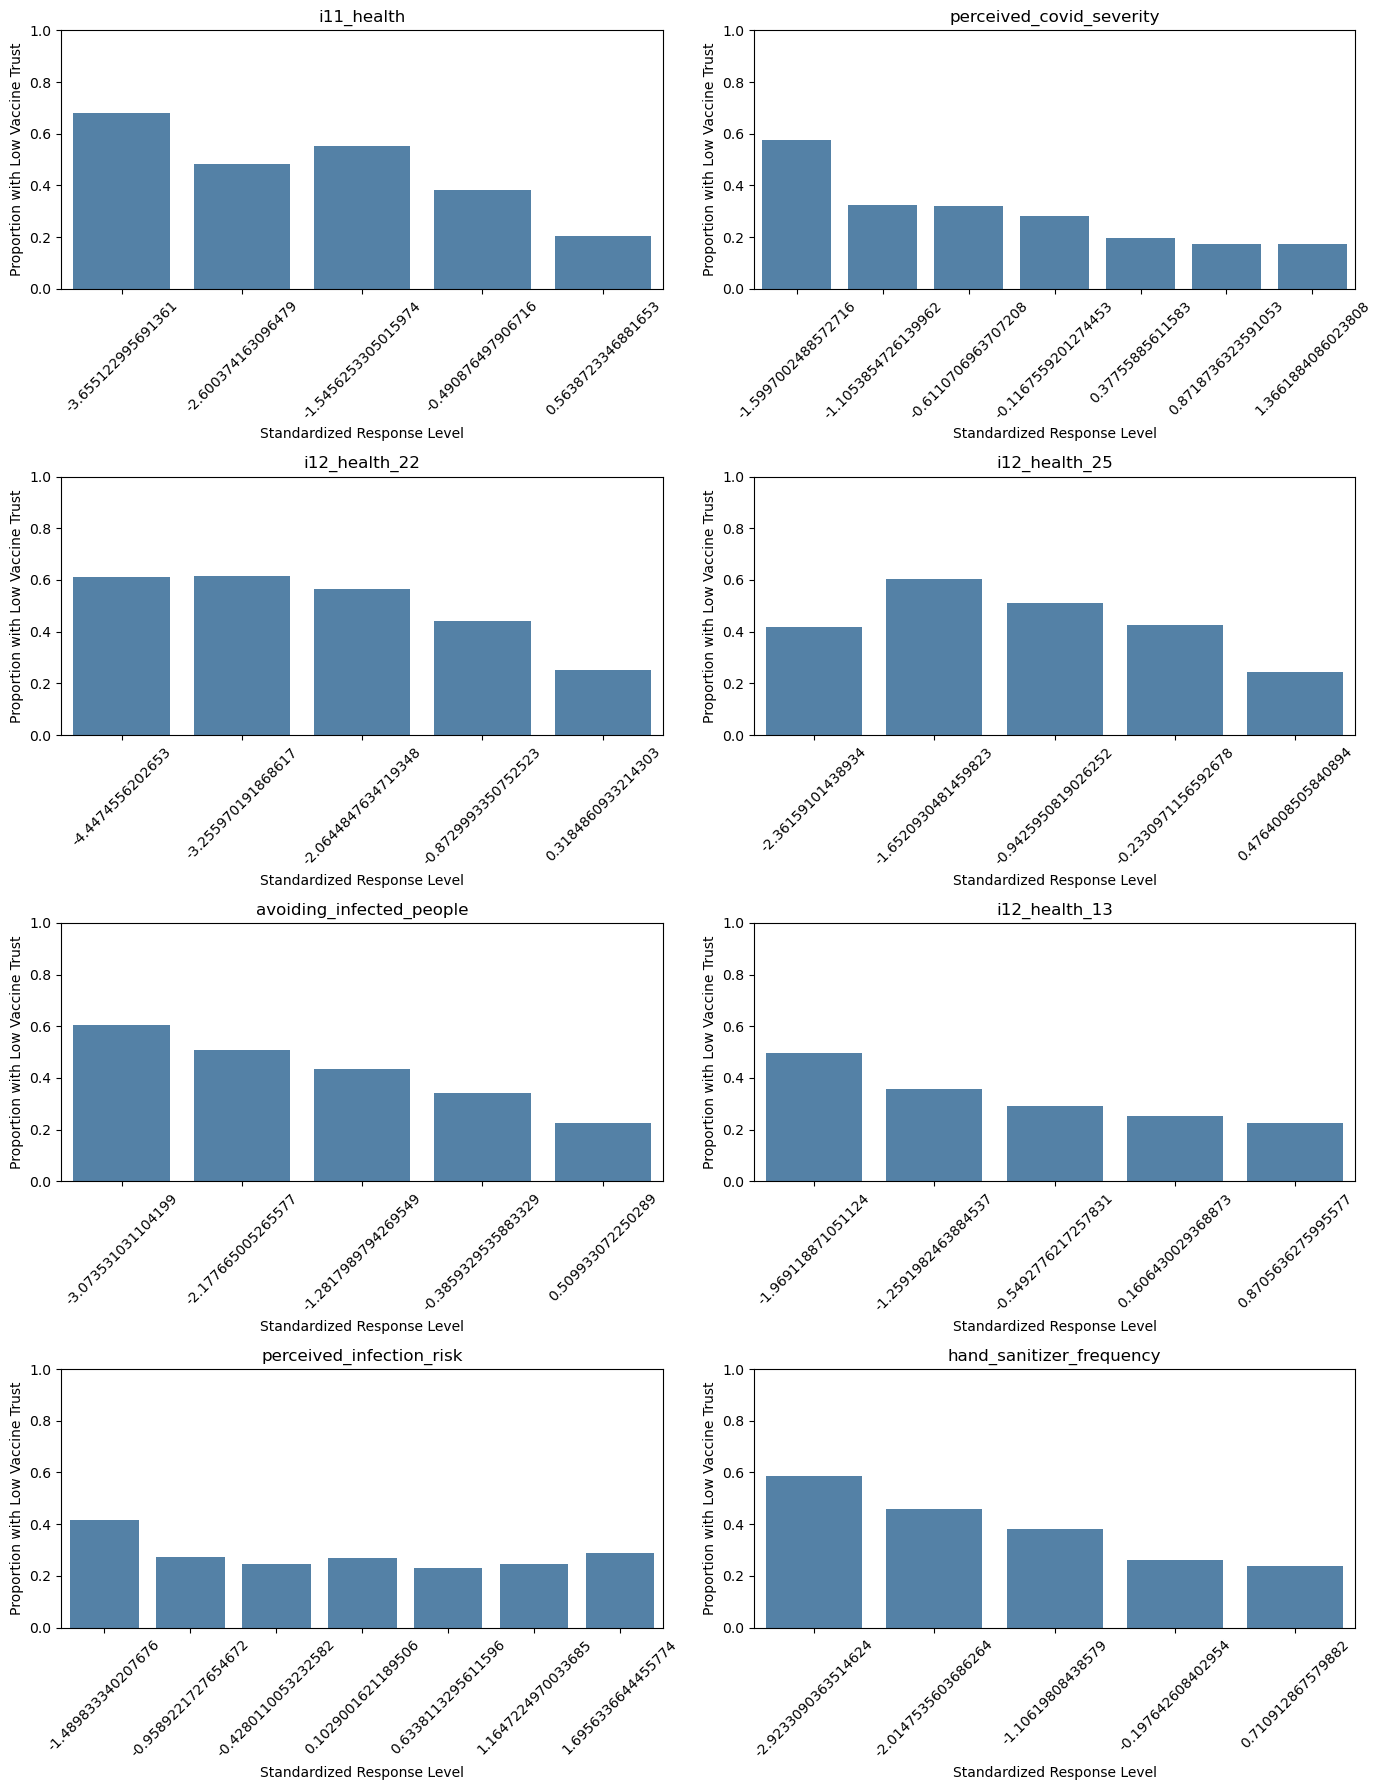

In [26]:
fig, axes = plt.subplots(4, 2, figsize=(14, 18))

axes = axes.flatten()

for i, feature in enumerate(ordinal_features):

    col = "ord__" + feature

    plot_data = (
        eda_data.groupby(col)["low_trust"]
        .agg(["mean", "count"])
        .reset_index()
        .sort_values(col)
    )

    sns.barplot(
        data=plot_data,
        x=col,
        y="mean",
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Standardized Response Level")
    axes[i].set_ylabel("Proportion with Low Vaccine Trust")
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

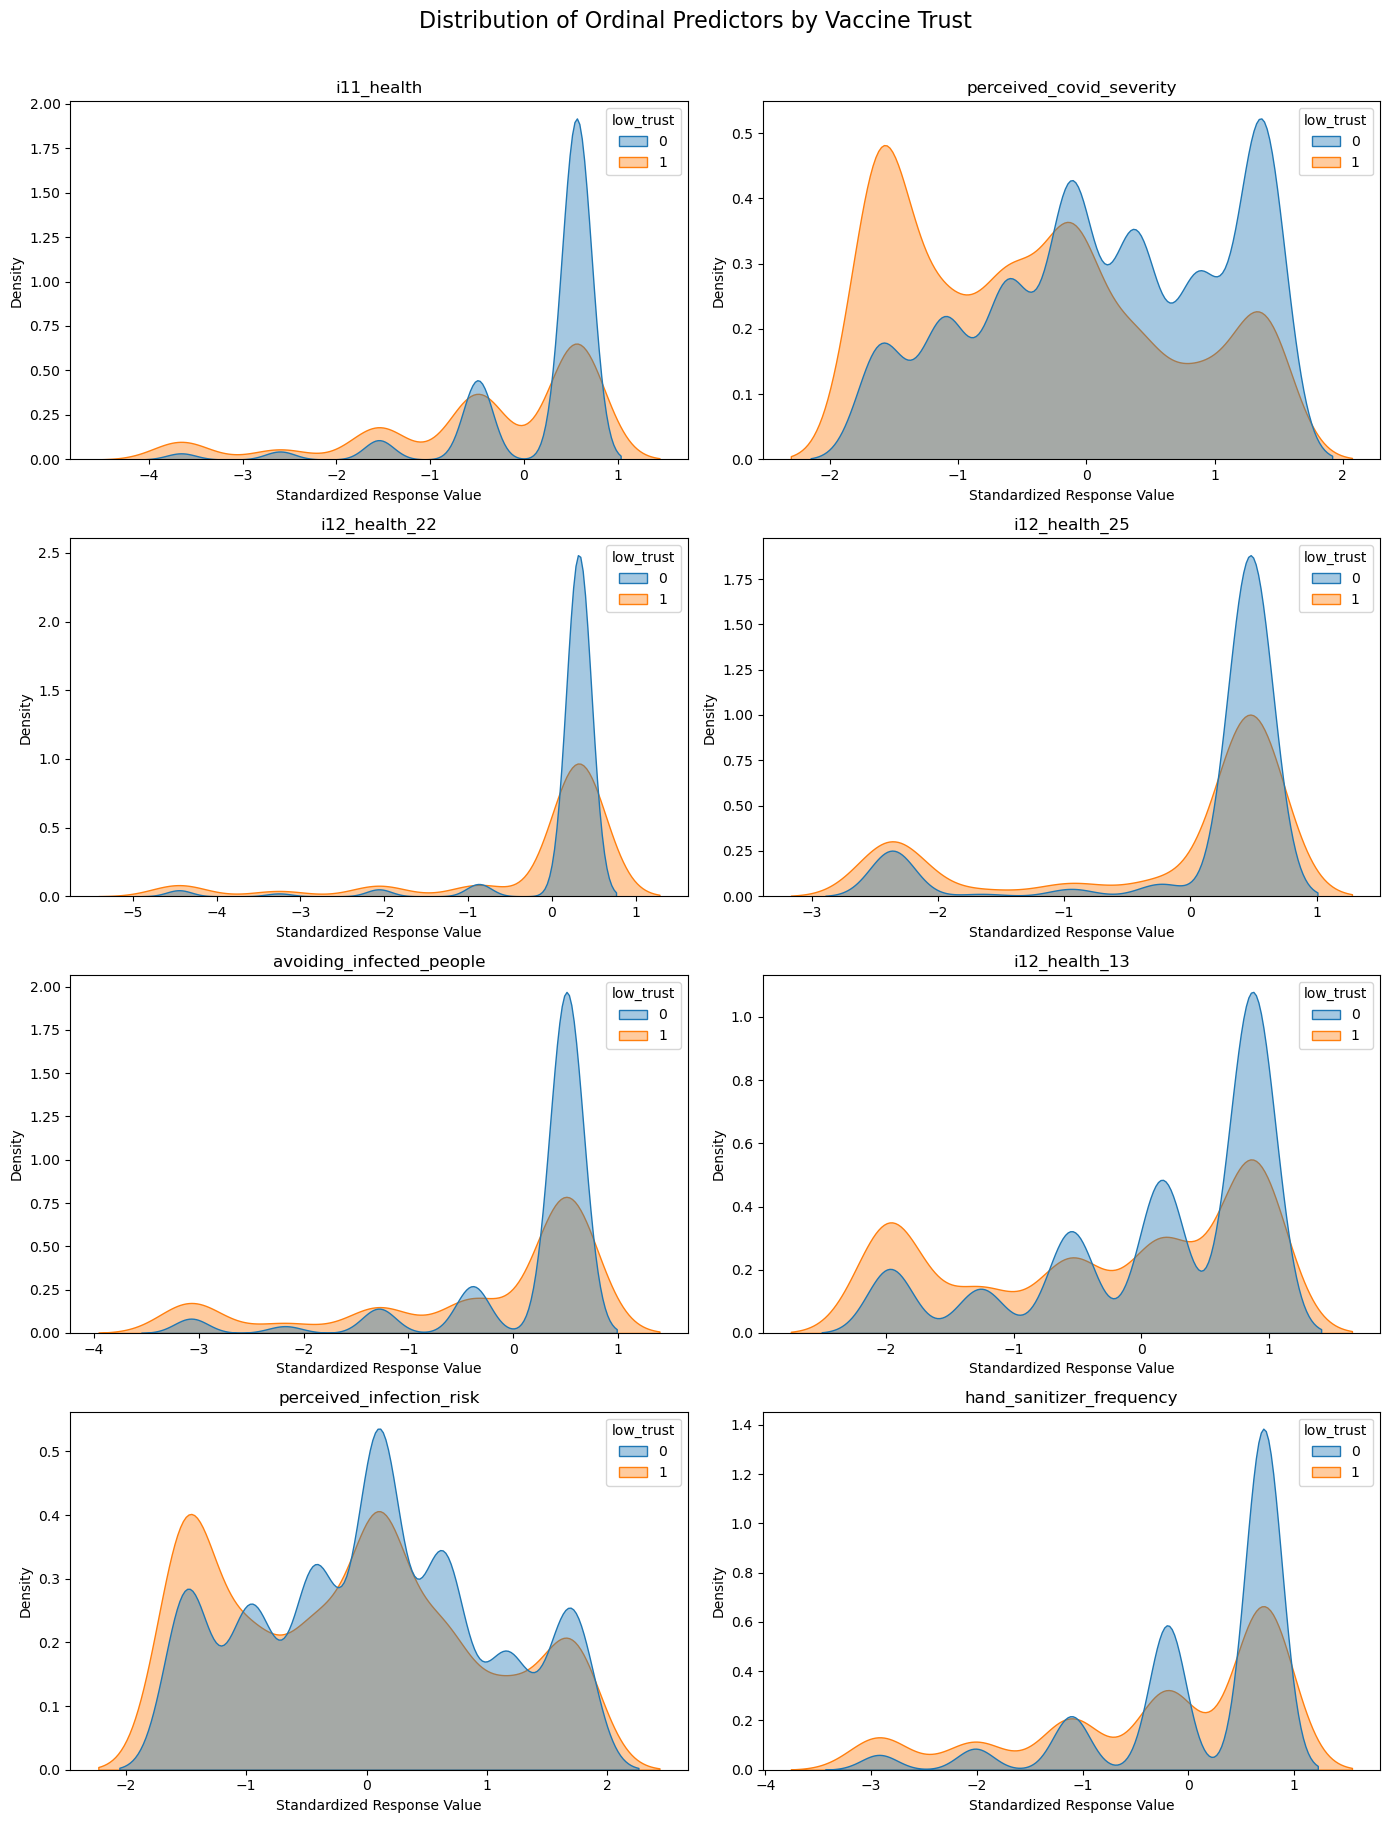

In [27]:
# Selected ordinal predictors
ordinal_features = [
    "i11_health",
    "perceived_covid_severity",
    "i12_health_22",
    "i12_health_25",
    "avoiding_infected_people",
    "i12_health_13",
    "perceived_infection_risk",
    "hand_sanitizer_frequency"
]

# Combine predictors and target
eda_data = X_train.copy()
eda_data["low_trust"] = y_train["low_trust"].to_numpy()

# Create density plots
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, feature in enumerate(ordinal_features):

    col = "ord__" + feature

    sns.kdeplot(
        data=eda_data,
        x=col,
        hue="low_trust",
        fill=True,
        common_norm=False,
        alpha=0.4,
        ax=axes[i]
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Standardized Response Value")
    axes[i].set_ylabel("Density")

plt.suptitle(
    "Distribution of Ordinal Predictors by Vaccine Trust",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [28]:
categorical_features = [
    "healthcare_system_confidence",
    "government_covid_response",
    "employment_status"
]

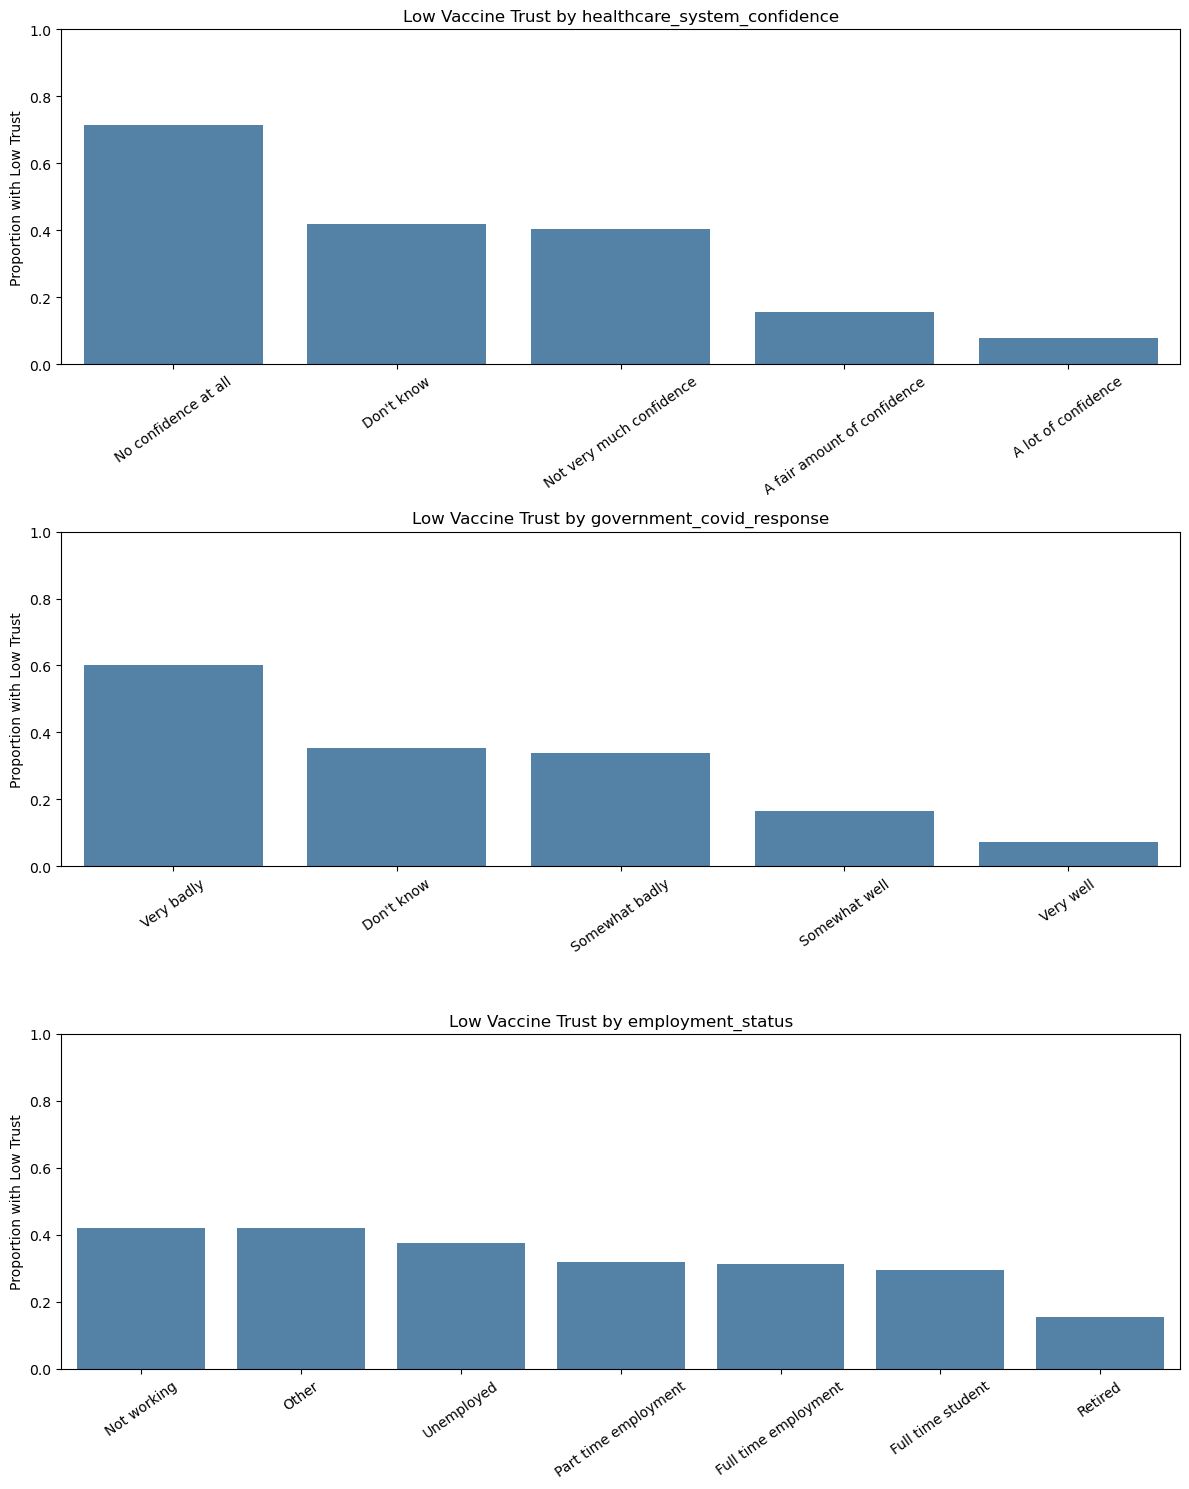

In [29]:
fig, axes = plt.subplots(3, 1, figsize=(12, 15))

for i, feature in enumerate(categorical_features):

    cols = [
        col for col in X_train.columns
        if col.startswith("cat__" + feature + "_")
    ]

    # Verify one-hot encoding
    assert (X_train[cols].sum(axis=1) == 1).all(), (
        f"Unexpected encoding for {feature}"
    )

    categories = (
        X_train[cols]
        .idxmax(axis=1)
        .str.replace("cat__" + feature + "_", "", regex=False)
    )

    plot_data = pd.DataFrame({
        "Category": categories,
        "low_trust": y_train["low_trust"].to_numpy()
    })

    summary = (
        plot_data.groupby("Category")["low_trust"]
        .agg(["mean", "count"])
        .reset_index()
        .sort_values("mean", ascending=False)
    )

    sns.barplot(
        data=summary,
        x="Category",
        y="mean",
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(
        f"Low Vaccine Trust by {feature}"
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Proportion with Low Trust")
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

### Three additional analyses

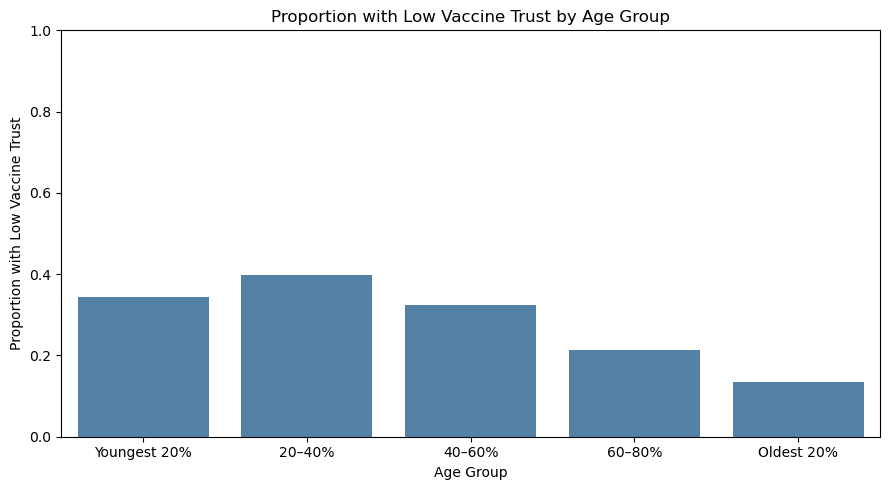

In [30]:
# Low vaccine trust among age groups with age quintiles
age_data = pd.DataFrame({
    "age": X_train["num__age"],
    "low_trust": y_train["low_trust"].to_numpy()
})

age_data["age_group"] = pd.qcut(
    age_data["age"],
    q=5,
    labels=[
        "Youngest 20%",
        "20–40%",
        "40–60%",
        "60–80%",
        "Oldest 20%"
    ]
)

age_summary = (
    age_data.groupby("age_group", observed=True)["low_trust"]
    .agg(["mean", "count"])
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_summary,
    x="age_group",
    y="mean",
    color="steelblue"
)

plt.title("Proportion with Low Vaccine Trust by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Proportion with Low Vaccine Trust")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

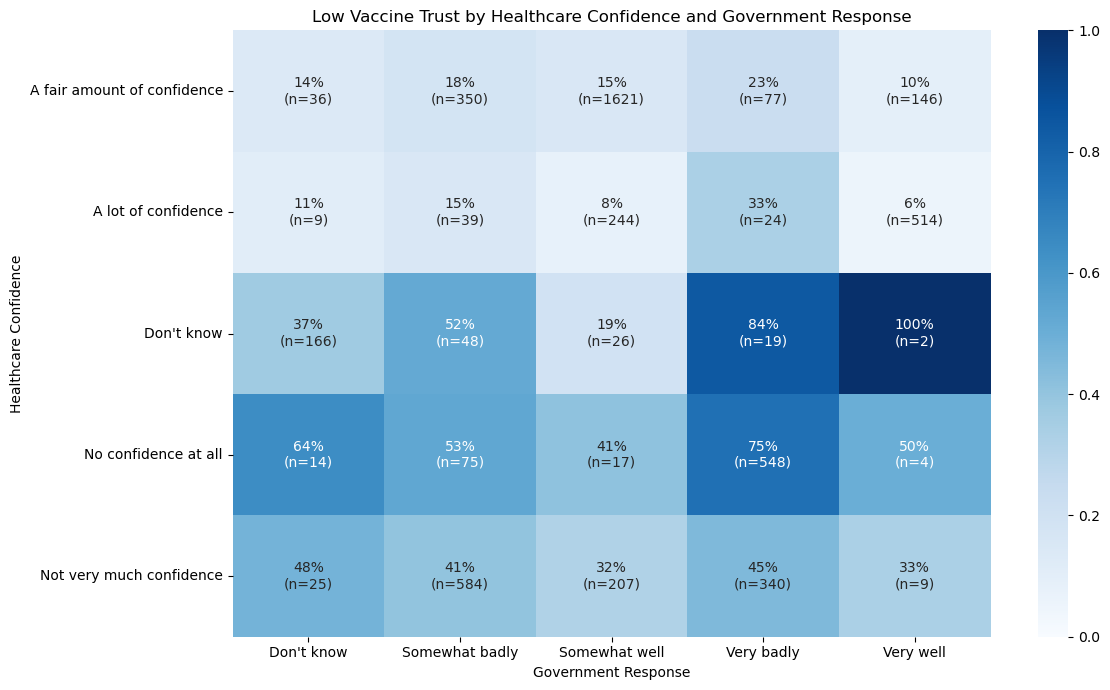

In [31]:
# Combined effect of healthcare confidence and government response

# Identify one-hot columns
health_cols = [
    col for col in X_train.columns
    if col.startswith("cat__healthcare_system_confidence_")
]

gov_cols = [
    col for col in X_train.columns
    if col.startswith("cat__government_covid_response_")
]

# Reconstruct original categories
health = (
    X_train[health_cols]
    .idxmax(axis=1)
    .str.replace(
        "cat__healthcare_system_confidence_", "",
        regex=False
    )
)

gov = (
    X_train[gov_cols]
    .idxmax(axis=1)
    .str.replace(
        "cat__government_covid_response_", "",
        regex=False
    )
)

combined_data = pd.DataFrame({
    "Healthcare Confidence": health,
    "Government Response": gov,
    "low_trust": y_train["low_trust"].to_numpy()
})

# Proportion of respondents with low trust
heatmap_data = combined_data.pivot_table(
    index="Healthcare Confidence",
    columns="Government Response",
    values="low_trust",
    aggfunc="mean"
)

# Number of respondents in each combination
counts = combined_data.groupby(
    ["Healthcare Confidence", "Government Response"]
).size().unstack()

# Annotate each cell with percentage and sample size
annotations = np.array([
    [
        f"{heatmap_data.iloc[i, j]:.0%}\n(n={int(counts.iloc[i, j])})"
        if pd.notna(heatmap_data.iloc[i, j]) else ""
        for j in range(heatmap_data.shape[1])
    ]
    for i in range(heatmap_data.shape[0])
])

plt.figure(figsize=(12, 7))

sns.heatmap(
    heatmap_data,
    annot=annotations,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title(
    "Low Vaccine Trust by Healthcare Confidence and Government Response"
)

plt.tight_layout()
plt.show()

In [32]:
# Number of observations behind ordinal bar charts
for feature in ordinal_features:

    col = "ord__" + feature

    summary = (
        eda_data.groupby(col)["low_trust"]
        .agg(
            Low_Trust_Proportion="mean",
            Observations="count"
        )
    )

    print(f"\n{feature}")
    print(summary.round(3))


i11_health
                 Low_Trust_Proportion  Observations
ord__i11_health                                    
-3.655123                       0.682           157
-2.600374                       0.484           126
-1.545625                       0.554           352
-0.490876                       0.382          1040
 0.563872                       0.203          3469

perceived_covid_severity
                               Low_Trust_Proportion  Observations
ord__perceived_covid_severity                                    
-1.599700                                     0.574           688
-1.105385                                     0.322           521
-0.611071                                     0.321           651
-0.116756                                     0.282           974
 0.377559                                     0.195           706
 0.871874                                     0.172           546
 1.366188                                     0.174          1058

i12

### FINAL PROCESS

1- The dataset initially had: 5 numerical columns, 31 ordinal columns, and 72 one-hot encoded columns.

2- Three main approaches have been used for feature selection:

    2.1- Mutual Information were calculated to identify variables with potentially informative relationships with vaccine trust. An initial shortlist of approximately 15 predictors was created.

    2.2- Pearson correlations were conducted among the shortlisted numerical and ordinal variables to identify potentially redundant variables. Several i12_health variables were moderately to strongly correlated, suggesting overlapping information.

    2.3- Cramér's V was calculated between healthcare system confidence and perceptions of the government's COVID-19 response. The resulting value of 0.595 (p < 0.001) indicated a strong association, suggesting potential redundancy. However, they were provisionally ranked using the maximum mutual information score of their one-hot encoded columns, rather than their joint mutual information.

### KEY EDA FINDINGS

1- Institutional confidence is strongly associated with vaccine trust:

    - Healthcare system confidence and perceptions of the government's COVID-19 response show clear relationships with trust. Although these predictors were strongly associated with one another, the combined heatmap suggested that healthcare confidence may still provide additional information within government-response categories, and vice versa. Both variables were therefore retained for further modeling.

2- Perceived COVID-19 severity and preventive behaviors look informative:

    - Perceived COVID-19 severity showed a clear relationship with vaccine trust. The proportion of respondents with low vaccine trust declined from approximately 57% at the lowest response level to approximately 17% at the highest level.

    - Avoiding infected people and hand sanitizer frequency showed clear associations with vaccine trust. Both variables were retained as promising predictors, although they may contain some overlapping behavioral information.

3- Age looks to be relevant:

    - Respondents with low vaccine trust tend to be younger.

    - The oldest 20% of respondents exhibited approximately 14% low vaccine trust, compared with approximately 35–40% among the two youngest quintiles.

4- Some other predictors don't seem too relevant:

    - Employment status and perceived infection risk appear less useful individually.

    - Employment status also showed differences between categories, but some of this variation may overlap with age. Age was therefore prioritized in the reduced feature set.

5- Additional variables:

    - Several i12_health variables and i11_health showed meaningful associations with vaccine trust. Correlation analysis revealed substantial overlap among some of these variables. For example, i12_health_13 and i12_health_27 had a correlation of approximately 0.734. Rather than including every highly ranked variable, a smaller representative set was selected for further testing.

### RECOMMENDED FEATURE SET

1- Starting model:

    -healthcare_system_confidence
    -government_covid_response
    -i11_health
    -perceived_covid_severity
    -age
    -avoiding_infected_people
    -hand_sanitizer_frequency
    -i12_health_13
    -i12_health_22
    -i12_health_25

2- Option 2 - Expanded model:

    -All 10 predictors above
    -perceived_infection_risk
    -employment_status

3- Option 3 - Compact model: Take out the last four variables from the list.

4- Option 4 - Full model: 61 predictors

    -Aim: Determine whether dimensionality reduction actually improves KNN performance.

    